<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Select the region of interest (ROI) of this dataset and save it as `rois/<dataset>/data.zarr` + `metadata.csv`.
> - **Manuscript panels:** Fig. 1A (dataset collection); input to all downstream analyses
> - **Inputs:** Raw vendor output in `rois/raw/`
> - **Outputs:** `rois/<dataset>/data.zarr`, `metadata.csv`
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

## Import packages

In [3]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys


from troutpy_reproducibility.roi_processing import *

## Read main path to .zarr file

In [5]:
inpath = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/raw/xenium_opsc_v1"
sdata = spatialdata_io.xenium(inpath)

output_path = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_opsc_v1"

INFO     reading                                                                                                   
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/raw/xenium_opsc_v1/cell_feature_matrix.h5  


<tifffile.TiffFile 'morphology_focus_0000.ome.tif'> OME series failed to read 'ch0001_atp1a1_cd45_e-cadherin.ome.tif', raised FileNotFoundError(2, 'No such file or directory'). Missing data are zeroed
<tifffile.TiffFile 'morphology_focus_0000.ome.tif'> OME series failed to read 3 files


We decide to keep the data in a unified scale (um), which then can be transformated to 'global' coordinates using the according transformation. This global transformation is specially useful for matching the sales of transcripts with ie images

In [7]:
sdata["table"]

AnnData object with n_obs × n_vars = 205082 × 477
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

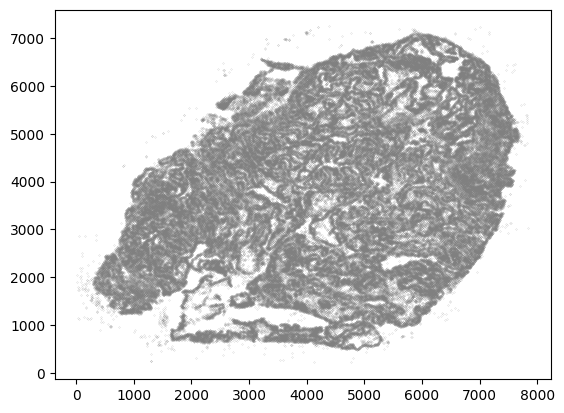

In [6]:
# Visualize using global coordinates
local_coords = sdata["table"].obsm["spatial"]
# In case it's needed, chec transformations
# print(  get_transformation(sdata["nucleus_boundaries"]))
spat = [g[0] for g in sdata["table"].obsm["spatial"]]
spat2 = [g[1] for g in sdata["table"].obsm["spatial"]]
plt.scatter(spat, spat2, s=0.01, c="grey")

In [16]:
# ROI selection
bb_xmin = 10000  # mix x
bb_ymin = 5000  # min y
bb_xmax = 20019  # max x
bb_ymax = 15809.9  # max y

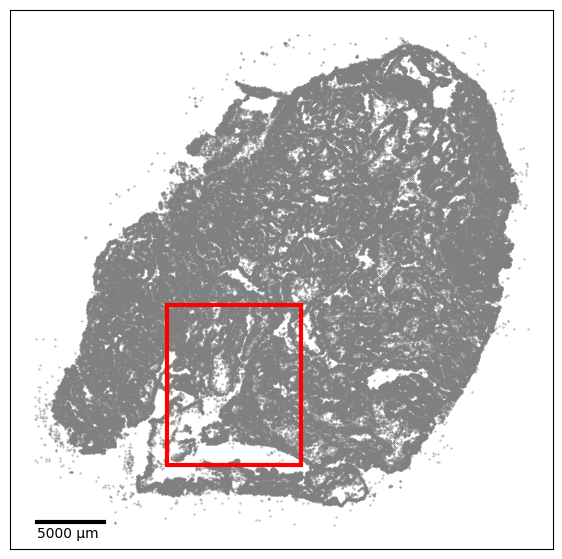

In [17]:
plot_spatial_with_box_and_scale(
    spatial_coords=sdata["table"].obsm["spatial"], bb_xmin=bb_xmin, bb_xmax=bb_xmax, bb_ymin=bb_ymin, bb_ymax=bb_ymax
)

Next, we select the ROI of interest

In [60]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],
    target_coordinate_system="global",
)

# Save metadata
metadata = generate_metadata(
    sdata=cropped_sdata,
    sample_id="human_opsc",
    species="Hommo Sapiens",
    technology="Xenium",
    segmentation_method="multimodal",
    roi_name="roi_hs_opsc_v1",
    tissue="ovary",
    disease="opsc",
)

rechunk_sdata(cropped_sdata)

Processing image: morphology_focus
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: nucleus_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: cell_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...


In [61]:
cropped_sdata.images["morphology_focus"]['scale0'].image

<xarray.DataArray 'image' (c: 4, y: 10810, x: 10019)> Size: 866MB
dask.array<rechunk-merge, shape=(4, 10810, 10019), dtype=uint16, chunksize=(1, 512, 512), chunktype=numpy.ndarray>
Coordinates:
  * c        (c) <U22 352B 'DAPI' ... 'AlphaSMA/Vimentin'
  * y        (y) float64 86kB 0.5 1.5 2.5 3.5 ... 1.081e+04 1.081e+04 1.081e+04
  * x        (x) float64 80kB 0.5 1.5 2.5 3.5 ... 1.002e+04 1.002e+04 1.002e+04
Attributes:
    transform:  {'global': Sequence \n    Translation (y, x)\n        [ 5000....

In [64]:
sdata

SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 34184, 36968), (4, 17092, 18484), (4, 8546, 9242), (4, 4273, 4621), (4, 2136, 2310)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (34184, 36968), (17092, 18484), (8546, 9242), (4273, 4621), (2136, 2310)
│     └── 'nucleus_labels': DataTree[yx] (34184, 36968), (17092, 18484), (8546, 9242), (4273, 4621), (2136, 2310)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (205082, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (205082, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (196390, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (205082, 477)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), cell_circles (Shapes), nucleus_boundaries (Shape

In [65]:
# troutpy converter to xenium
troutpy.pp.xenium_converter(cropped_sdata, unassigned_tag="UNASSIGNED")

In [67]:
cropped_sdata

SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 10810, 10019), (4, 5405, 5010), (4, 2702, 2505), (4, 1351, 1252), (4, 676, 626)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (10810, 10019), (5405, 5010), (2702, 2505), (1351, 1252), (676, 626)
│     └── 'nucleus_labels': DataTree[yx] (10810, 10019), (5405, 5010), (2702, 2505), (1351, 1252), (676, 626)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 15) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (24286, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (24078, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (23131, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (24078, 477)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), cell_circles (Shapes), nucleus_boundaries (Shapes)

In [71]:
del cropped_sdata['morphology_focus']

In [72]:
# Define output paths
zarr_path = os.path.join(output_path, "data.zarr")
metadata_path = os.path.join(output_path, "metadata.csv")

cropped_sdata.write(zarr_path, overwrite=True)
metadata.to_csv(metadata_path, index=False)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_opsc_v1/data.zarr              


In [73]:
cropped_sdata

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_opsc_v1/data.zarr
├── Labels
│     ├── 'cell_labels': DataTree[yx] (10810, 10019), (5405, 5010), (2702, 2505), (1351, 1252), (676, 626)
│     └── 'nucleus_labels': DataTree[yx] (10810, 10019), (5405, 5010), (2702, 2505), (1351, 1252), (676, 626)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 15) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (24286, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (24078, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (23131, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (24078, 477)
with coordinate systems:
    ▸ 'global', with elements:
        cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), cell_circles (Shapes), nucleus_boundaries (Shapes)

In [28]:
# Print the coordinate system names (keys) available for your image
print(sdata.images["morphology_focus"].transformations.keys())

# Print the full details of the transformations
print(sdata.images["morphology_focus"].transformations)

AttributeError: 'DataTree' object has no attribute 'transformations'

In [40]:
np.array(sdata.images["morphology_focus"]['scale0'].image)

AttributeError: 'DataArray' object has no attribute 'values'

In [44]:
cropped_sdata['transcripts'].compute()

,x,y,z,gene,cell_id,qv,codeword_category,overlaps_nucleus,transcript_id,fov_name,is_gene,nucleus_distance,codeword_index,control_probe,overlaps_cell
0,4012.140625,1713.968750,17.828125,ABCA10,defdnhfh-1,37.75,custom_gene,True,281818574849461,Y11,True,0.000000,477,True,True
1,2969.218750,1795.671875,16.484375,ABCA10,aegkekpn-1,40.00,custom_gene,True,281861524183471,Y9,True,0.000000,477,True,True
2,4252.140625,2295.437500,16.031250,ABCA10,jfbkfnbg-1,33.00,custom_gene,False,281874408809068,Z12,True,0.843750,477,True,True
3,3025.515625,2636.937500,18.515625,ABCA10,nmfcclia-1,27.25,custom_gene,True,281865818877534,Z10,True,0.000000,477,True,True
4,3084.812500,2673.140625,18.890625,ABCA10,iimaopke-1,36.00,custom_gene,True,281865818877845,Z10,True,0.000000,477,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21912647,2932.609375,1669.140625,16.968750,NegControlCodeword_0525,ipomjffg-1,14.75,negative_control_codeword,True,281861524835829,Y9,False,0.000000,525,True,True
21912648,2856.531250,1651.921875,16.984375,NegControlCodeword_0527,aeiajiin-1,14.50,negative_control_codeword,True,281861524149326,Y9,False,0.000000,527,True,True
21912649,2988.937500,1541.093750,17.421875,NegControlCodeword_0533,ipohghan-1,18.00,negative_control_codeword,False,281861524555588,Y9,False,0.250000,533,True,True
21912650,2989.515625,1589.609375,19.062500,NegControlCodeword_0537,agcfjpbf-1,18.75,negative_control_codeword,False,281861524864964,Y9,False,0.734375,537,True,True


In [45]:
# Force Dask to compute the image data arrays into memory
for scale in cropped_sdata.images["morphology_focus"].keys():
    # This replaces the lazy Dask array with a concrete in-memory array
    cropped_sdata.images["morphology_focus"][scale]["image"].load()

AttributeError: 'NoneType' object has no attribute 'asarray'

In [58]:
# ROI selection
bb_xmin = 10000  # min x
bb_ymin = 5000  # min y
bb_xmax = 20019  # max x
bb_ymax = 15809.9  # max y

In [52]:
# 1. Grab your target bounding coordinates in pixels (since it's Identity space)
# Example: x_min, x_max, y_min, y_max = 1000, 5000, 2000, 6000

# 2. Extract the uncropped raw sdata image object
img_tree = sdata.images["morphology_focus"]

# 3. Manually slice out your ROI from the xarray DataTree scales
# (Standard label-slicing often avoids the complex block-indexing bug)
for scale in img_tree.keys():
    cropped_sdata.images["morphology_focus"][scale] = img_tree[scale].sel(
        x=slice(bb_xmin, bb_xmax), 
        y=slice(bb_ymin, bb_ymax)
    )



In [55]:
from spatialdata.models import Image3DModel

# 1. Grab only the high-resolution scale0 DataArray from the original data
raw_scale0 = sdata.images["morphology_focus"]["scale0"]["image"]


In [57]:
raw_scale0

<xarray.DataArray 'image' (c: 4, y: 34184, x: 36968)> Size: 10GB
dask.array<rechunk-merge, shape=(4, 34184, 36968), dtype=uint16, chunksize=(1, 4096, 4096), chunktype=numpy.ndarray>
Coordinates:
  * c        (c) <U22 352B 'DAPI' ... 'AlphaSMA/Vimentin'
  * y        (y) float64 273kB 0.5 1.5 2.5 3.5 ... 3.418e+04 3.418e+04 3.418e+04
  * x        (x) float64 296kB 0.5 1.5 2.5 3.5 ... 3.697e+04 3.697e+04 3.697e+04
Attributes:
    transform:  {'global': Identity }